# Exercise 59 – Random graphs and how to tell them apart

**Week 12 · Graphs and message passing**

Random 2D "molecules" are generated by adding nodes one at a time, each within
a cutoff distance of an existing node but not too close to any. Nodes closer
than the cutoff are connected.

Two graphs are the same (*isomorphic*) if they differ only in how the nodes
are numbered. Isomorphic graphs have the same adjacency-matrix eigenvalues,
so comparing sorted spectra is a quick test. Using it we count how many
different 5-node graphs the generator produces.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.graphs import adjacency_spectrum, plot_graph, random_graph, same_spectrum, unique_graphs

torch.manual_seed(0);

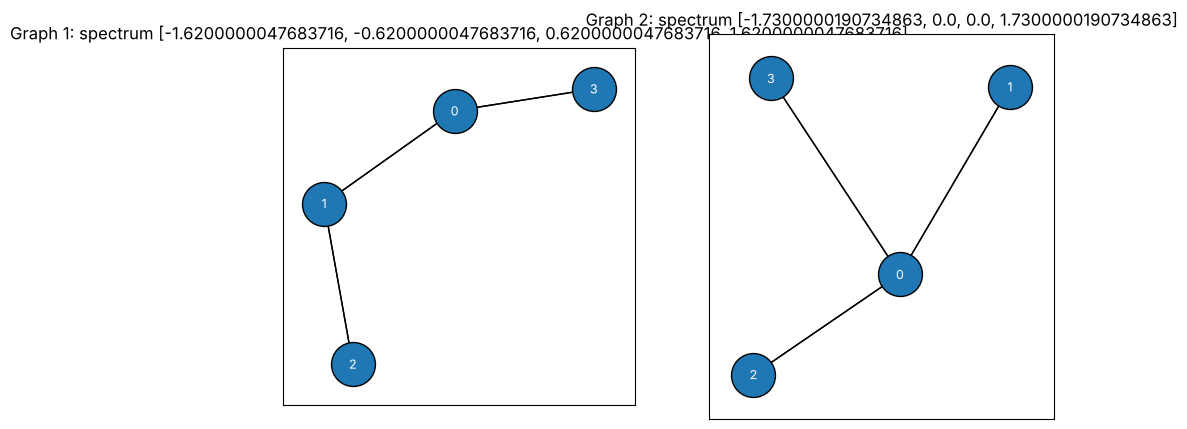

edge_index of graph 1:
 tensor([[0, 0, 1, 1, 2, 3],
        [1, 3, 0, 2, 1, 0]])
same spectrum: False


In [2]:
g1, g2 = random_graph(4), random_graph(4)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, g, name in zip(axes, [g1, g2], ["Graph 1", "Graph 2"]):
    plot_graph(ax, g, size=1000, title=f"{name}: spectrum {adjacency_spectrum(g).round(2).tolist()}")
plt.show()
print("edge_index of graph 1:\n", g1.edge_index)
print("same spectrum:", same_spectrum(g1, g2))

Relabelling the nodes of a graph does not change its spectrum:

In [3]:
perm = torch.tensor([3, 1, 0, 2])
inverse = torch.argsort(perm)
relabelled = g1.clone()
relabelled.edge_index = inverse[g1.edge_index]
relabelled.pos = g1.pos[perm]
print("relabelled graph has the same spectrum:", same_spectrum(g1, relabelled))

relabelled graph has the same spectrum: True


## How many different 5-node graphs?

13 different graphs among 1000 random 5-node graphs


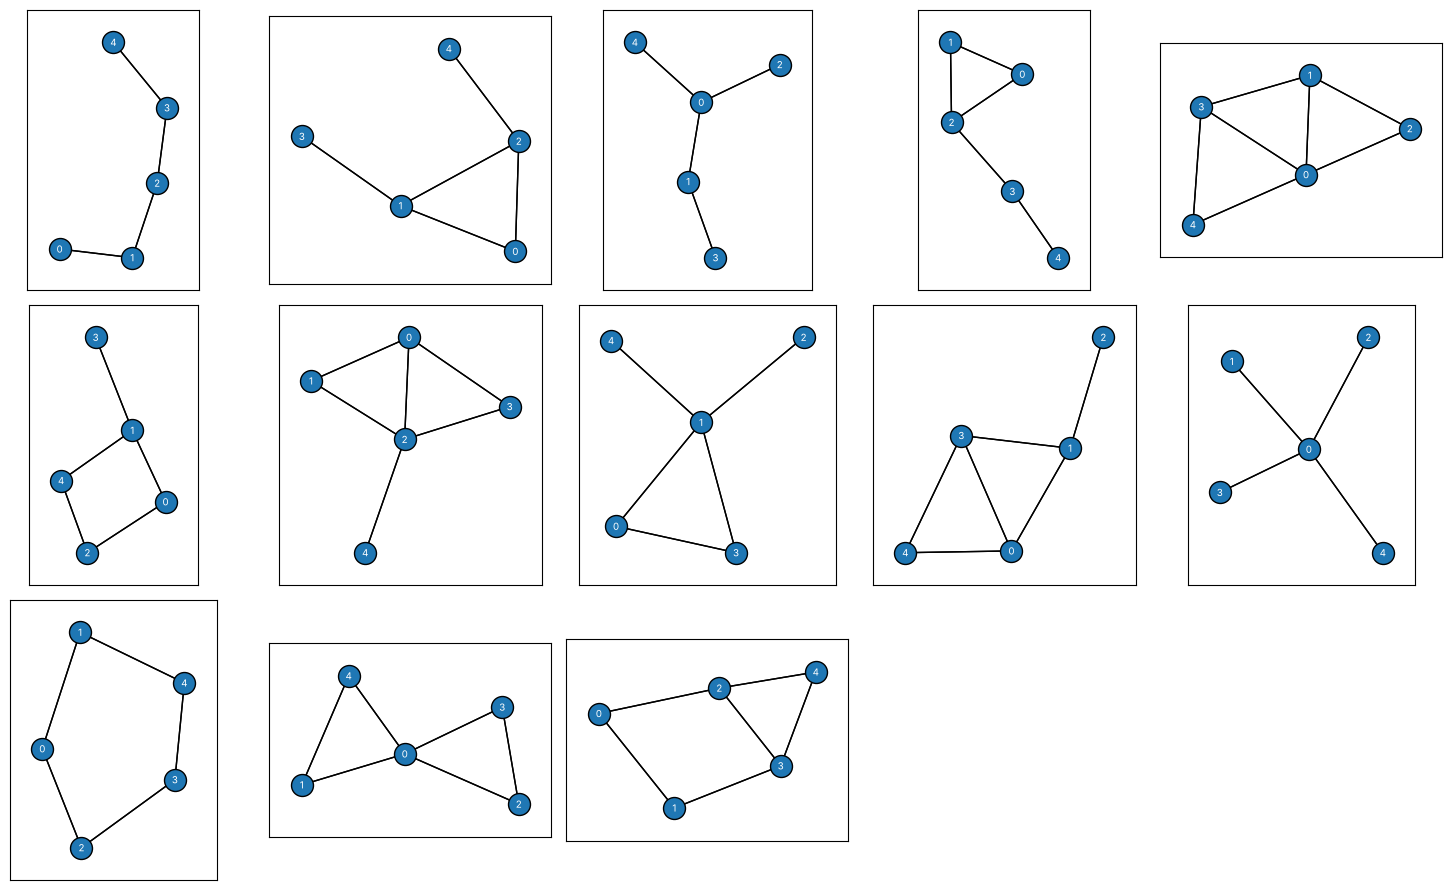

In [4]:
graphs = [random_graph(5) for _ in range(1000)]
unique = unique_graphs(graphs)
print(f"{len(unique)} different graphs among {len(graphs)} random 5-node graphs")

ncols = 5
nrows = -(-len(unique) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
for ax in axes.flat:
    ax.axis("off")
for ax, g in zip(axes.flat, unique):
    ax.axis("on")
    plot_graph(ax, g, size=250, fontsize=7)
fig.tight_layout()
plt.show()